In [15]:
import matplotlib.pyplot as plt
import json, glob, os
import numpy as np
import pandas as pd
from collections import defaultdict

In [16]:
# Путь к папке с json-файлами. Поменяй под свой реальный путь.
# Если структура такая: custom_experiment_results/full_exp/*.json — оставь как есть.
# Если что-то другое — посмотри, что печатает glob ниже, и поправь.
RESULTS_DIR = 'final_cifar10_results/'
SHOW_EMA = False            # для splus_sf показывать отдельно test_acc_ema
EXCLUDE_METHODS = {'splus_noema_sf'}   # методы, которые не показываем на графиках

files = sorted(glob.glob(f'{RESULTS_DIR}/**/*.json', recursive=True))
print(f'Found {len(files)} files')
for f in files[:30]:
    print('  ', f)
if len(files) > 30:
    print(f'  ... и ещё {len(files) - 30}')

runs = []
for f in files:
    with open(f, encoding='utf-8') as fh:
        d = json.load(fh)
    if d['cfg']['method'] in EXCLUDE_METHODS:
        continue
    d['_file'] = f
    runs.append(d)

# Группировка по (method, lr)
groups = defaultdict(list)
for r in runs:
    groups[(r['cfg']['method'], r['cfg']['lr'])].append(r)

print(f'\nTotal runs: {len(runs)} (excluded: {sorted(EXCLUDE_METHODS)})')
print(f'Groups (method, lr): {len(groups)}')
for key in sorted(groups):
    seeds = sorted(r['cfg']['seed'] for r in groups[key])
    div = sum(r.get('diverged', False) for r in groups[key])
    print(f'  {key[0]:20s} lr={key[1]:<8g} seeds={seeds}  diverged={div}')

Found 15 files
   final_cifar10_results/adamw_cos_lr0.001_s0.json
   final_cifar10_results/adamw_cos_lr0.001_s1.json
   final_cifar10_results/adamw_cos_lr0.001_s2.json
   final_cifar10_results/adamw_sf_lr0.001_s0.json
   final_cifar10_results/adamw_sf_lr0.001_s1.json
   final_cifar10_results/adamw_sf_lr0.001_s2.json
   final_cifar10_results/splus_lr0.3_s0.json
   final_cifar10_results/splus_lr0.3_s1.json
   final_cifar10_results/splus_lr0.3_s2.json
   final_cifar10_results/splus_noema_sf_lr0.3_s0.json
   final_cifar10_results/splus_noema_sf_lr0.3_s1.json
   final_cifar10_results/splus_noema_sf_lr0.3_s2.json
   final_cifar10_results/splus_sf_lr0.3_s0.json
   final_cifar10_results/splus_sf_lr0.3_s1.json
   final_cifar10_results/splus_sf_lr0.3_s2.json

Total runs: 12 (excluded: ['splus_noema_sf'])
Groups (method, lr): 4
  adamw_cos            lr=0.001    seeds=[0, 1, 2]  diverged=0
  adamw_sf             lr=0.001    seeds=[0, 1, 2]  diverged=0
  splus                lr=0.3      seeds=[0, 

In [17]:
def stack(group, metric):
    """Собрать матрицу (n_seeds, T) — обрезаем по минимальной длине."""
    L = min(len(r[metric]) for r in group)
    return np.array([r[metric][:L] for r in group])

def lbl(method, lr):
    return f'{method} (lr={lr:g})'

def plot_mean_std(metric, title, ylabel, ema=False, logy=False):
    plt.figure(figsize=(12, 7))
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    for (method, lr), group in sorted(groups.items()):
        key = metric + ('_ema' if ema else '')
        if key not in group[0]:
            continue
        arr = stack(group, key)
        m, s = arr.mean(0), arr.std(0)
        x = np.arange(len(m))
        line, = plt.plot(x, m, label=f'{lbl(method, lr)} | n={len(group)}')
        if len(group) > 1:
            plt.fill_between(x, m - s, m + s, alpha=0.2, color=line.get_color())
    if logy:
        plt.yscale('log')
    plt.grid(True, which='both', alpha=0.4)
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

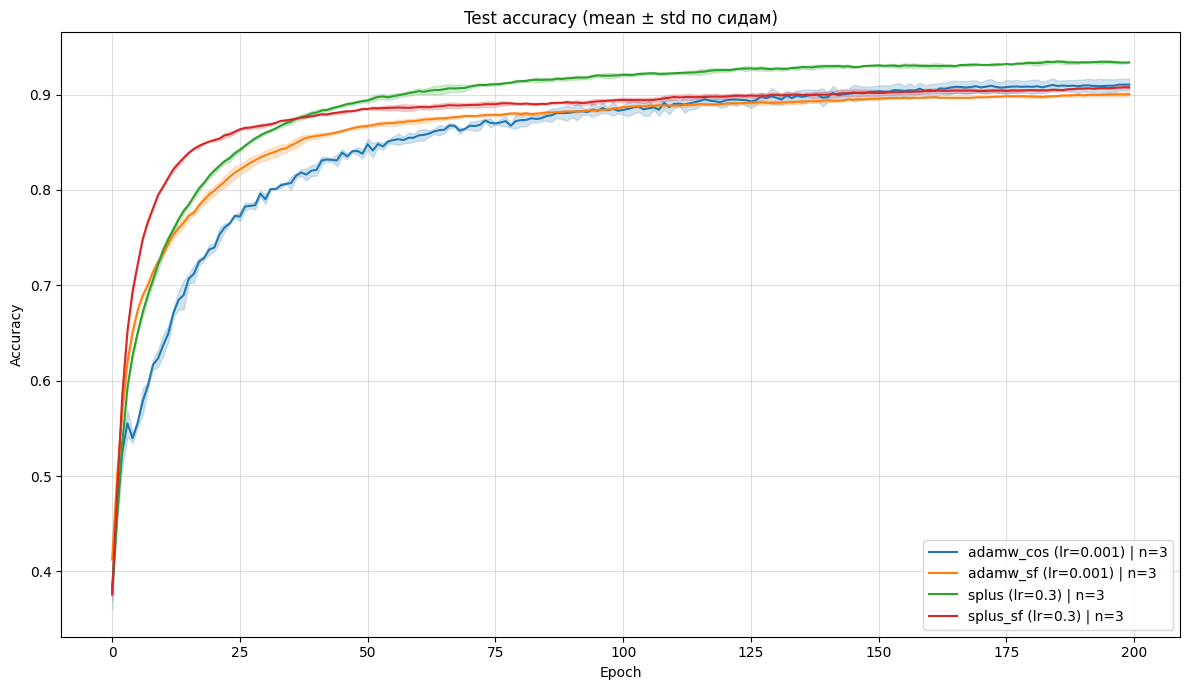

In [18]:
plot_mean_std('test_acc', 'Test accuracy (mean ± std по сидам)', 'Accuracy')

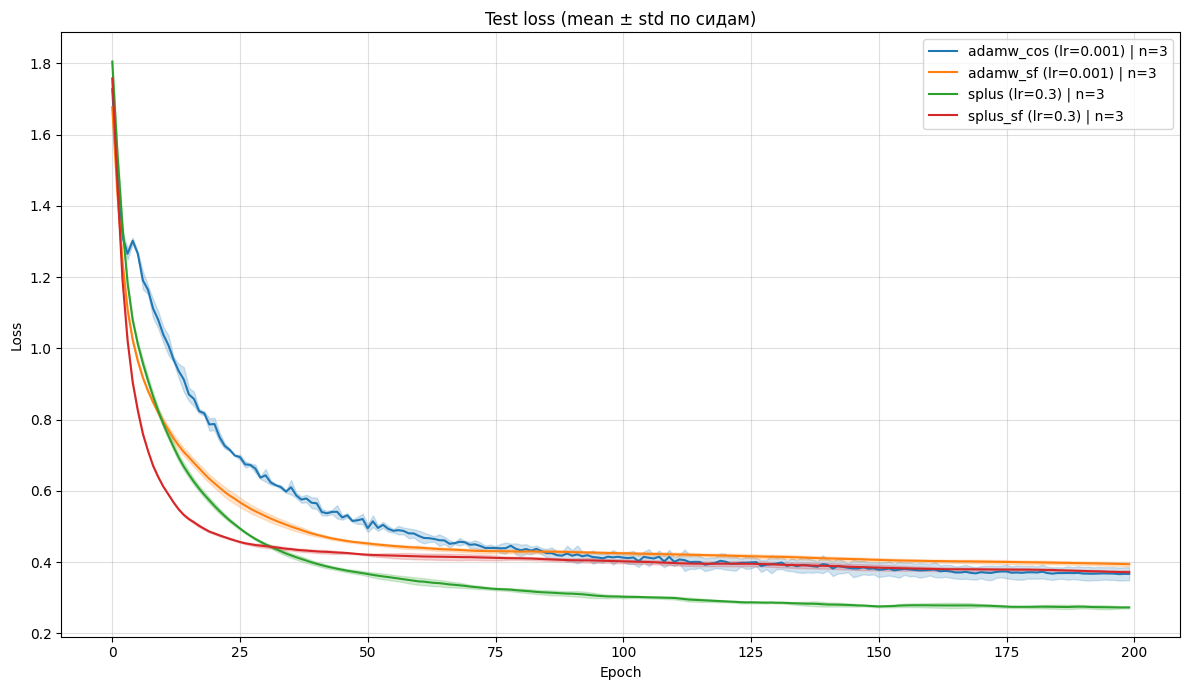

In [19]:
plot_mean_std('test_loss', 'Test loss (mean ± std по сидам)', 'Loss')

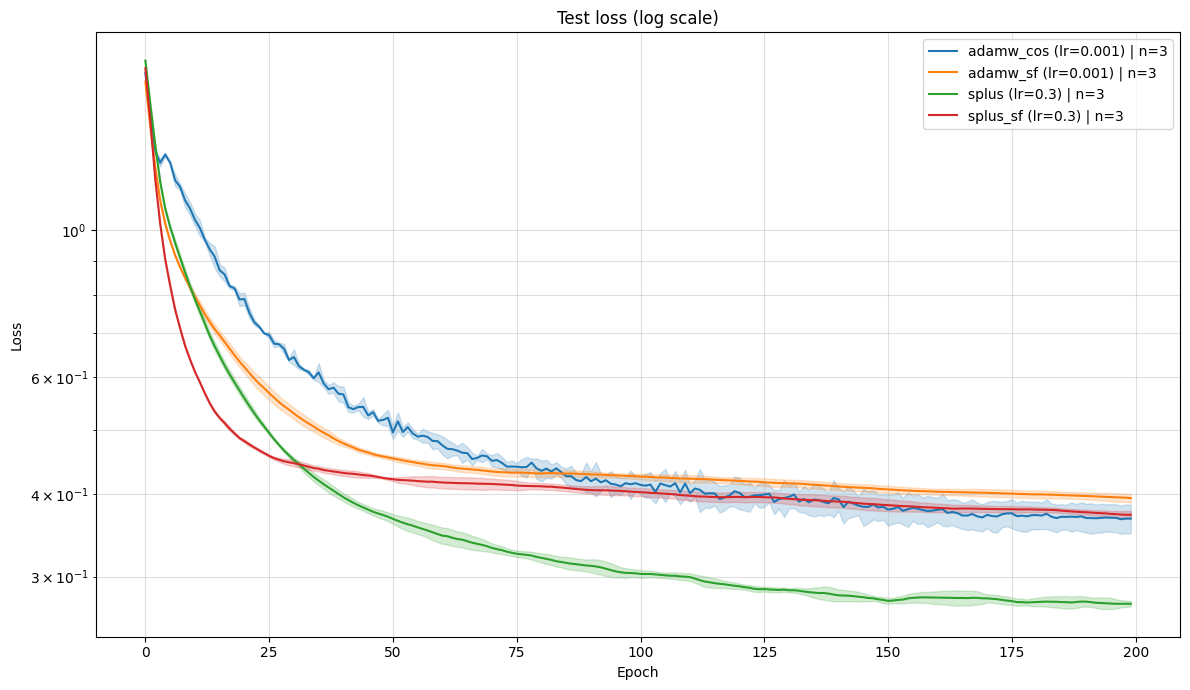

In [20]:
plot_mean_std('test_loss', 'Test loss (log scale)', 'Loss', logy=True)

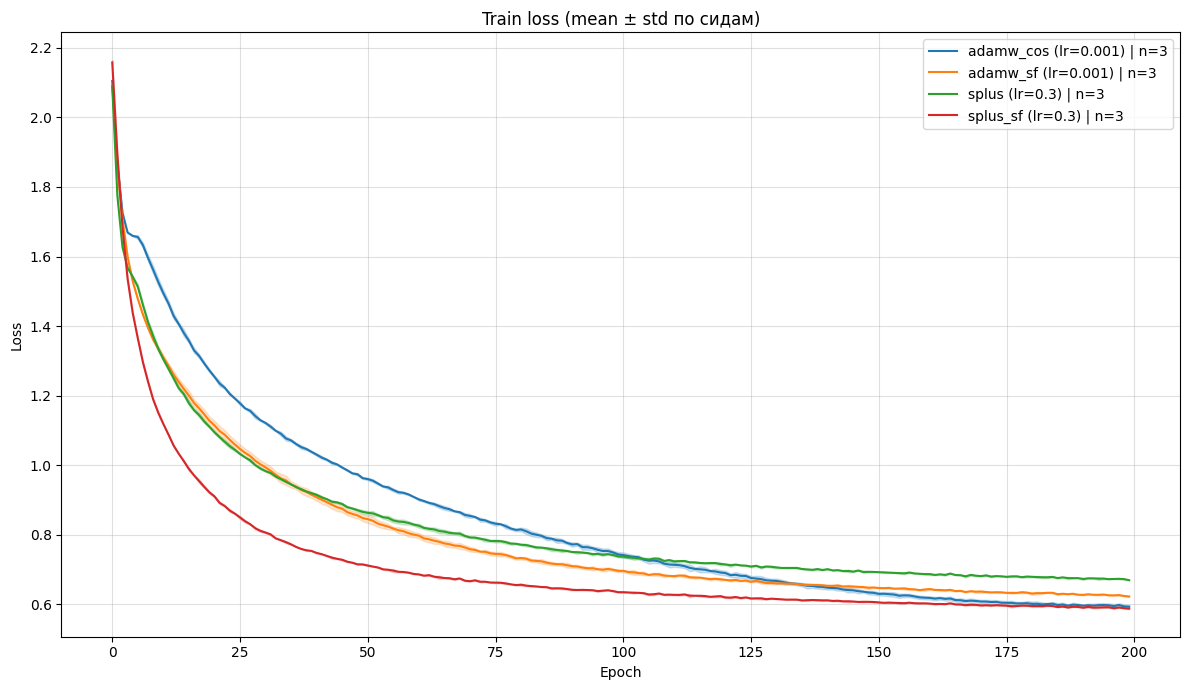

In [21]:
plot_mean_std('train_loss', 'Train loss (mean ± std по сидам)', 'Loss')

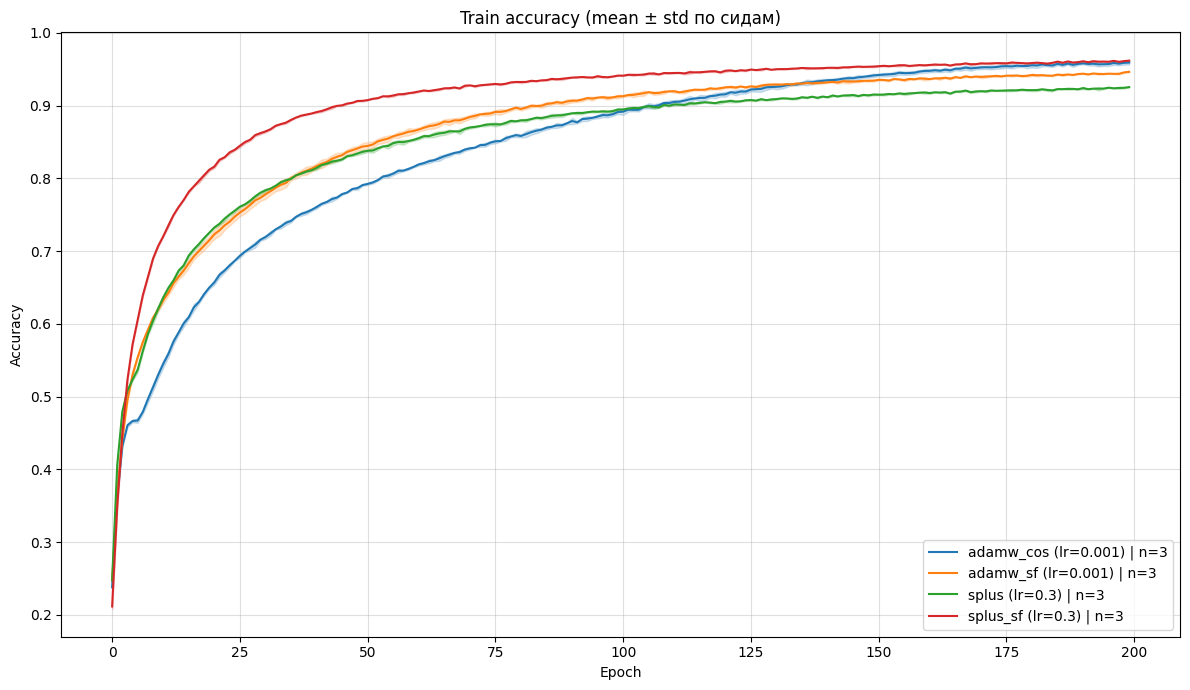

In [22]:
plot_mean_std('train_acc', 'Train accuracy (mean ± std по сидам)', 'Accuracy')

In [23]:
rows = []
for (method, lr), group in sorted(groups.items()):
    final_acc  = np.array([r['test_acc'][-1]  for r in group])
    final_loss = np.array([r['test_loss'][-1] for r in group])
    best_acc   = np.array([max(r['test_acc']) for r in group])
    best_ep    = np.array([int(np.argmax(r['test_acc'])) for r in group])
    times      = np.array([r['time'] for r in group])
    diverged   = sum(r.get('diverged', False) for r in group)

    row = {
        'Method': method,
        'LR': f'{lr:g}',
        'Seeds': len(group),
        'Test acc mean': final_acc.mean(),
        'Test acc std': final_acc.std(),
        'Test acc best (mean)': best_acc.mean(),
        'Best epoch (mean)': best_ep.mean(),
        'Test loss mean': final_loss.mean(),
        'Time (s)': times.mean(),
        'Diverged': diverged,
    }
    if 'test_acc_ema' in group[0]:
        ema = np.array([r['test_acc_ema'][-1] for r in group])
        row['EMA acc mean'] = ema.mean()
        row['EMA acc std'] = ema.std()
    rows.append(row)

df = (pd.DataFrame(rows)
        .sort_values('Test acc mean', ascending=False)
        .reset_index(drop=True))
df

,Method,LR,Seeds,Test acc mean,Test acc std,Test acc best (mean),Best epoch (mean),Test loss mean,Time (s),Diverged
0,splus,0.3,3,0.933767,0.000613,0.935533,187.666667,0.272947,1663.575052,0
1,adamw_cos,0.001,3,0.910467,0.006494,0.910867,190.666667,0.367177,1240.003761,0
2,splus_sf,0.3,3,0.907600,0.001344,0.907800,195.666667,0.371870,1915.634469,0
3,adamw_sf,0.001,3,0.900400,0.001780,0.900833,195.333333,0.394221,1236.265884,0


In [24]:
df_pretty = pd.DataFrame()
df_pretty['Method'] = df['Method']
df_pretty['LR'] = df['LR']
df_pretty['Seeds'] = df['Seeds']
df_pretty['Test acc'] = df.apply(
    lambda r: f"{r['Test acc mean']:.4f} ± {r['Test acc std']:.4f}", axis=1)
df_pretty['Test acc (best)'] = df['Test acc best (mean)'].map(lambda v: f'{v:.4f}')
df_pretty['Best epoch'] = df['Best epoch (mean)'].map(lambda v: f'{v:.0f}')
df_pretty['Test loss'] = df['Test loss mean'].map(lambda v: f'{v:.4f}')
df_pretty['Time (s)'] = df['Time (s)'].map(lambda v: f'{v:.0f}')
df_pretty['Diverged'] = df['Diverged']
if 'EMA acc mean' in df.columns:
    df_pretty['EMA acc'] = df.apply(
        lambda r: f"{r['EMA acc mean']:.4f} ± {r['EMA acc std']:.4f}", axis=1)
df_pretty

,Method,LR,Seeds,Test acc,Test acc (best),Best epoch,Test loss,Time (s),Diverged
0,splus,0.3,3,0.9338 ± 0.0006,0.9355,188,0.2729,1664,0
1,adamw_cos,0.001,3,0.9105 ± 0.0065,0.9109,191,0.3672,1240,0
2,splus_sf,0.3,3,0.9076 ± 0.0013,0.9078,196,0.3719,1916,0
3,adamw_sf,0.001,3,0.9004 ± 0.0018,0.9008,195,0.3942,1236,0


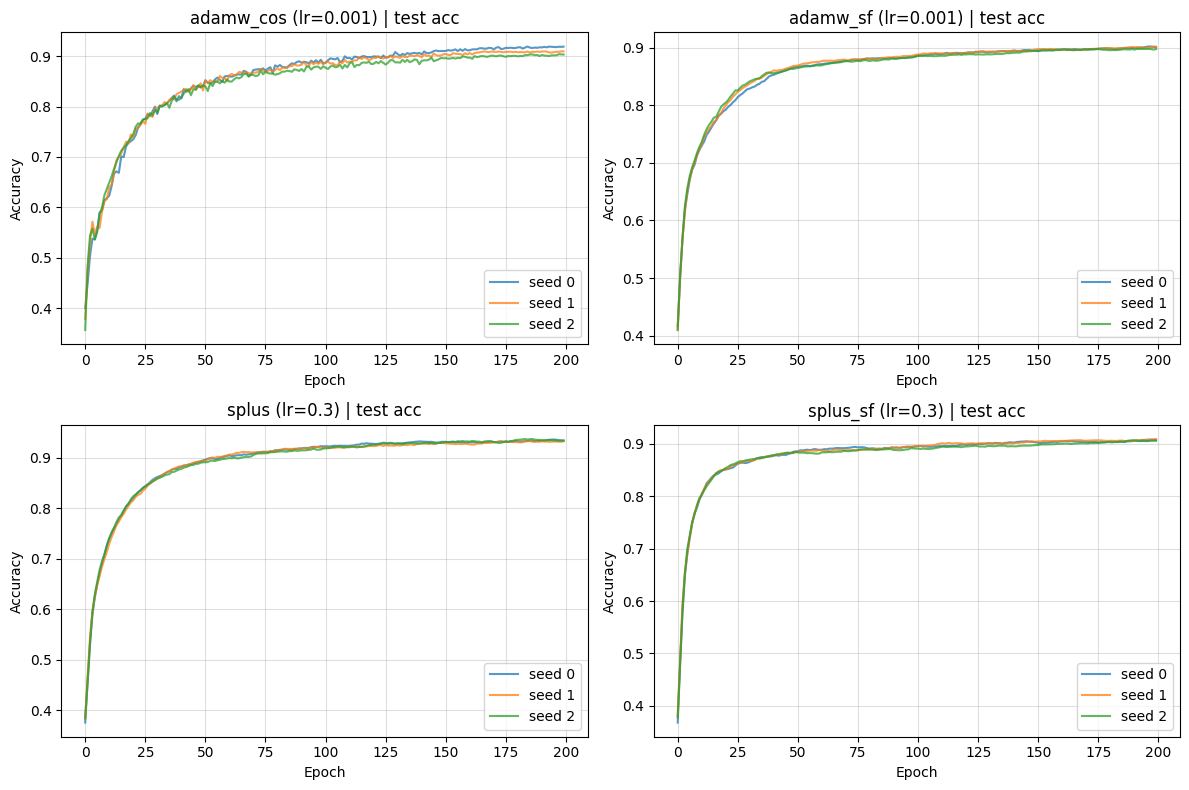

In [25]:
n = len(groups)
cols = 2
rows_ = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_, cols, figsize=(12, 4 * rows_), squeeze=False)
for ax, ((method, lr), group) in zip(axes.flat, sorted(groups.items())):
    for r in group:
        ax.plot(r['test_acc'], alpha=0.75, label=f"seed {r['cfg']['seed']}")
    ax.set_title(f'{lbl(method, lr)} | test acc')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.grid(True, alpha=0.4)
    ax.legend()
for ax in axes.flat[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

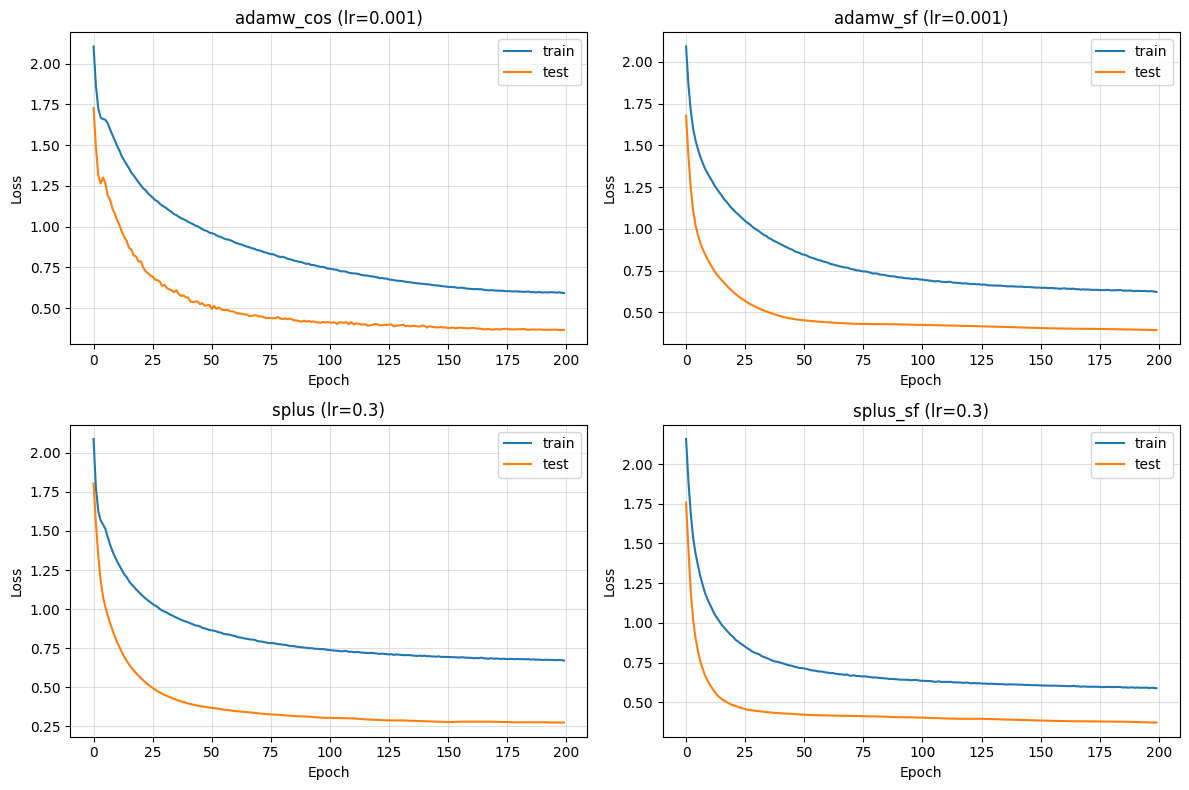

In [26]:
fig, axes = plt.subplots(rows_, cols, figsize=(12, 4 * rows_), squeeze=False)
for ax, ((method, lr), group) in zip(axes.flat, sorted(groups.items())):
    tr = stack(group, 'train_loss').mean(0)
    te = stack(group, 'test_loss').mean(0)
    x = np.arange(len(tr))
    ax.plot(x, tr, label='train')
    ax.plot(x, te, label='test')
    ax.set_title(f'{lbl(method, lr)}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.grid(True, alpha=0.4)
    ax.legend()
for ax in axes.flat[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()